In [35]:
from ucimlrepo import fetch_ucirepo
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler, OrdinalEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score,classification_report, recall_score, precision_score,accuracy_score, confusion_matrix

bank_marketing = fetch_ucirepo(id=222)

X = bank_marketing.data.features
y = bank_marketing.data.targets.squeeze()

df = X.copy()
df["y"] = y

print(df.head())
print(df.info())

   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married        NaN      no     1506     yes   no   
4   33           NaN   single        NaN      no        1      no   no   

  contact  day_of_week month  duration  campaign  pdays  previous poutcome   y  
0     NaN            5   may       261         1     -1         0      NaN  no  
1     NaN            5   may       151         1     -1         0      NaN  no  
2     NaN            5   may        76         1     -1         0      NaN  no  
3     NaN            5   may        92         1     -1         0      NaN  no  
4     NaN            5   may       198         1     -1         0      NaN  no  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to

In [4]:
print(df.isnull().sum())

age                0
job              288
marital            0
education       1857
default            0
balance            0
housing            0
loan               0
contact        13020
day_of_week        0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome       36959
y                  0
dtype: int64


In [5]:
eksik_sutunkar = [ "job", "education", "contact","poutcome"]

for sutun in eksik_sutunkar:
  df[sutun] = df[sutun].fillna("Unkown")

print(df.isnull().sum())
print(df["poutcome"].value_counts())

age            0
job            0
marital        0
education      0
default        0
balance        0
housing        0
loan           0
contact        0
day_of_week    0
month          0
duration       0
campaign       0
pdays          0
previous       0
poutcome       0
y              0
dtype: int64
poutcome
Unkown     36959
failure     4901
other       1840
success     1511
Name: count, dtype: int64


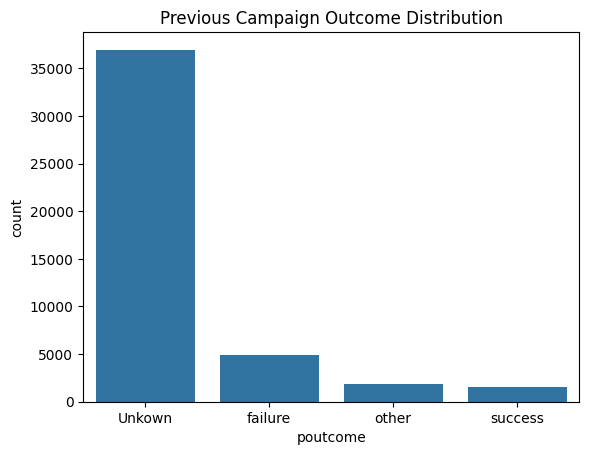

In [6]:
sns.countplot(data=df, x="poutcome")
plt.title("Previous Campaign Outcome Distribution")
plt.show()

In [7]:
kategorik_sutunlar = df.select_dtypes(
    include=["object"]
).columns.tolist()

sayisal_sutunlar = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Kategorik sütunlar:", kategorik_sutunlar)
print("Sayısal sütunlar:", sayisal_sutunlar)

Kategorik sütunlar: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']
Sayısal sütunlar: ['age', 'balance', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous']


In [9]:
#Durationu çıkarmamızın nedeni telefon konuşması yapmadan önce müşterinin hareketini belirleyebilmek.
X = df.drop(columns=["y", "duration"])
y = df["y"]

In [11]:
X_train_val, X_test, y_train_val, y_test = train_test_split(X,y,test_size=0.25,random_state=42,stratify=y)

In [12]:
X_train, X_val, y_train, y_val = train_test_split(X_train_val,y_train_val,test_size=0.25,random_state=42,stratify=y_train_val)

In [13]:
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (25431, 16)
Validation: (8477, 16)
Test: (11303, 16)


In [17]:
Scaler = StandardScaler()

In [19]:
categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

In [21]:
X_train_scaled = preprocessor.fit_transform(X_train)

X_val_scaled = preprocessor.transform(X_val)

X_test_scaled = preprocessor.transform(X_test)

In [22]:
print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

Train: (25431, 51)
Validation: (8477, 51)
Test: (11303, 51)


In [23]:
from sklearn.dummy import DummyClassifier

dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train_scaled, y_train)

dummy_pred = dummy_model.predict(X_val_scaled)

In [24]:
print("Baseline Accuracy:", accuracy_score(y_val, dummy_pred))

Baseline Accuracy: 0.882977468444025


In [25]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_val_scaled)

In [27]:
print("Accuracy:", accuracy_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred, pos_label="yes"))
print("Recall:", recall_score(y_val, y_pred, pos_label="yes"))
print("F1 Score:", f1_score(y_val, y_pred, pos_label="yes"))

print(classification_report(y_val, y_pred))

Accuracy: 0.9036215642326295
Precision: 0.6593806921675774
Recall: 0.3649193548387097
F1 Score: 0.4698247890979883
              precision    recall  f1-score   support

          no       0.92      0.98      0.95      7485
         yes       0.66      0.36      0.47       992

    accuracy                           0.90      8477
   macro avg       0.79      0.67      0.71      8477
weighted avg       0.89      0.90      0.89      8477



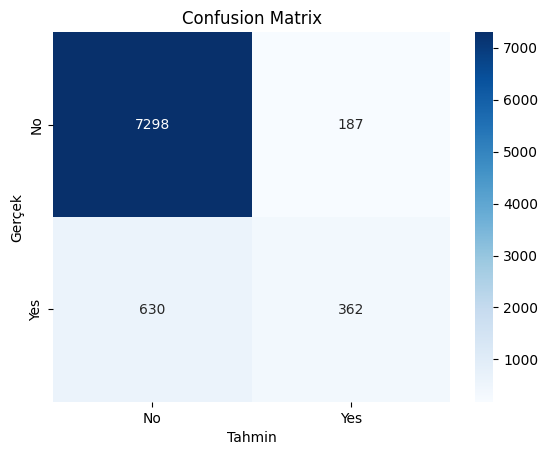

In [29]:
cm = confusion_matrix(y_val, y_pred, labels=["no", "yes"])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.title("Confusion Matrix")
plt.show()

In [30]:
balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

balanced_model.fit(X_train_scaled, y_train)

balanced_pred = balanced_model.predict(X_val_scaled)

In [31]:
print("Accuracy:", accuracy_score(y_val, balanced_pred))

print("Precision:", precision_score(
    y_val, balanced_pred, pos_label="yes"
))

print("Recall:", recall_score(
    y_val, balanced_pred, pos_label="yes"
))

print("F1 Score:", f1_score(
    y_val, balanced_pred, pos_label="yes"
))

Accuracy: 0.8425150406983603
Precision: 0.4148883374689826
Recall: 0.842741935483871
F1 Score: 0.5560359161955437


In [32]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Balanced Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_val, y_pred),
        accuracy_score(y_val, balanced_pred)
    ],
    "Precision": [
        precision_score(y_val, y_pred, pos_label="yes"),
        precision_score(y_val, balanced_pred, pos_label="yes")
    ],
    "Recall": [
        recall_score(y_val, y_pred, pos_label="yes"),
        recall_score(y_val, balanced_pred, pos_label="yes")
    ],
    "F1 Score": [
        f1_score(y_val, y_pred, pos_label="yes"),
        f1_score(y_val, balanced_pred, pos_label="yes")
    ]
})

print(comparison.round(3))

                          Model  Accuracy  Precision  Recall  F1 Score
0           Logistic Regression     0.904      0.659   0.365     0.470
1  Balanced Logistic Regression     0.843      0.415   0.843     0.556


In [33]:
from sklearn.metrics import roc_auc_score

normal_prob = model.predict_proba(X_val_scaled)[
    :, list(model.classes_).index("yes")
]

balanced_prob = balanced_model.predict_proba(X_val_scaled)[
    :, list(balanced_model.classes_).index("yes")
]

print("Normal ROC-AUC:", roc_auc_score(y_val, normal_prob))

print("Balanced ROC-AUC:",roc_auc_score(y_val, balanced_prob))

Normal ROC-AUC: 0.9138323690391537
Balanced ROC-AUC: 0.915217262481953


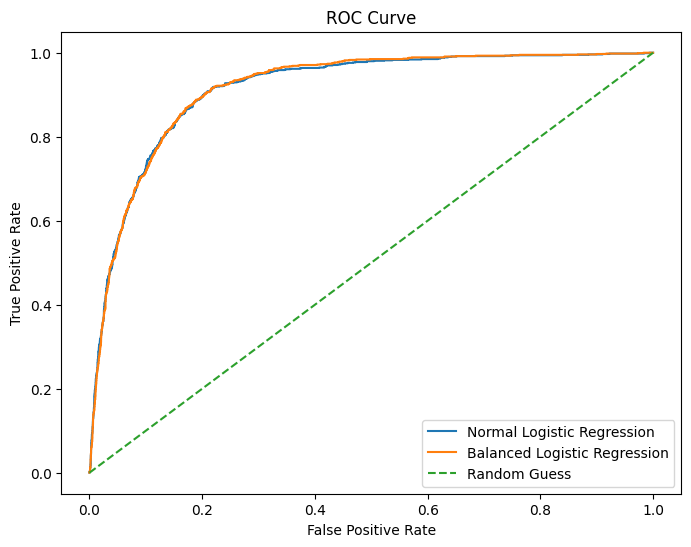

In [34]:
from sklearn.metrics import roc_curve

fpr_normal, tpr_normal, _ = roc_curve(
    y_val, normal_prob, pos_label="yes"
)

fpr_balanced, tpr_balanced, _ = roc_curve(
    y_val, balanced_prob, pos_label="yes"
)

plt.figure(figsize=(8, 6))

plt.plot(fpr_normal, tpr_normal, label="Normal Logistic Regression")
plt.plot(fpr_balanced, tpr_balanced, label="Balanced Logistic Regression")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [36]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_model.fit(X_train_scaled, y_train)

rf_pred = rf_model.predict(X_val_scaled)

In [37]:
rf_prob = rf_model.predict_proba(X_val_scaled)[
    :, list(rf_model.classes_).index("yes")
]

print("Accuracy:", accuracy_score(y_val, rf_pred))
print("Precision:", precision_score(y_val, rf_pred, pos_label="yes"))
print("Recall:", recall_score(y_val, rf_pred, pos_label="yes"))
print("F1 Score:", f1_score(y_val, rf_pred, pos_label="yes"))
print("ROC-AUC:", roc_auc_score(y_val, rf_prob))

print(classification_report(y_val, rf_pred))

Accuracy: 0.9023239353544886
Precision: 0.6767241379310345
Recall: 0.3165322580645161
F1 Score: 0.43131868131868134
ROC-AUC: 0.9308733730902665
              precision    recall  f1-score   support

          no       0.92      0.98      0.95      7485
         yes       0.68      0.32      0.43       992

    accuracy                           0.90      8477
   macro avg       0.80      0.65      0.69      8477
weighted avg       0.89      0.90      0.89      8477



In [38]:
feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15))

                  Feature  Importance
3           num__duration    0.345090
1            num__balance    0.075866
0                num__age    0.072182
2        num__day_of_week    0.065457
4           num__campaign    0.033462
49  cat__poutcome_success    0.029799
5              num__pdays    0.029226
34       cat__contact_nan    0.024557
32  cat__contact_cellular    0.019345
6           num__previous    0.019237
28        cat__housing_no    0.016579
29       cat__housing_yes    0.015692
43         cat__month_may    0.012073
36         cat__month_aug    0.011893
35         cat__month_apr    0.011677


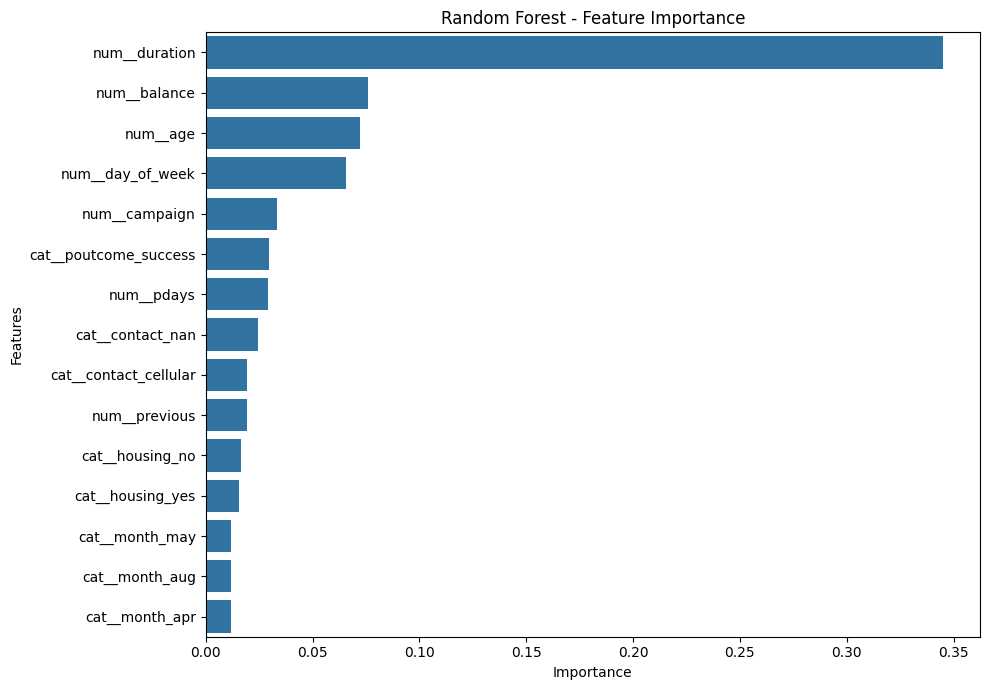

In [39]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [41]:
print(X.columns)
print(numerical_columns)

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day_of_week', 'month', 'duration', 'campaign',
       'pdays', 'previous', 'poutcome'],
      dtype='object')
['age', 'balance', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous']


In [42]:
X = df.drop(columns=["y", "duration"])
y = df["y"]

In [43]:
print(X.columns)
print(numerical_columns)

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day_of_week', 'month', 'campaign', 'pdays',
       'previous', 'poutcome'],
      dtype='object')
['age', 'balance', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous']


In [44]:
print(df["contact"].value_counts(dropna=False))

contact
cellular     29285
NaN          13020
telephone     2906
Name: count, dtype: int64


In [45]:
categorical_cols = df.select_dtypes(include=["object"]).columns

df[categorical_cols] = df[categorical_cols].fillna("unknown")

print(df["contact"].value_counts(dropna=False))

contact
cellular     29285
unknown      13020
telephone     2906
Name: count, dtype: int64


In [46]:
X = df.drop(columns=["y", "duration"])
y = df["y"]

categorical_columns = X.select_dtypes(include=["object"]).columns.tolist()

numerical_columns = X.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Numerical:", numerical_columns)
print("Categorical:", categorical_columns)

Numerical: ['age', 'balance', 'day_of_week', 'campaign', 'pdays', 'previous']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [47]:
X_train_val, X_test, y_train_val, y_test = train_test_split(X,y,test_size=0.25,random_state=42,stratify=y)

In [48]:
X_train, X_val, y_train, y_val = train_test_split(X_train_val,y_train_val,test_size=0.25,random_state=42,stratify=y_train_val)

In [49]:
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (25431, 15)
Validation: (8477, 15)
Test: (11303, 15)


In [50]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

In [51]:
X_train_scaled = preprocessor.fit_transform(X_train)

X_val_scaled = preprocessor.transform(X_val)

X_test_scaled = preprocessor.transform(X_test)

In [52]:
print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

Train: (25431, 50)
Validation: (8477, 50)
Test: (11303, 50)


In [53]:
dummy_model = DummyClassifier(strategy="most_frequent")

dummy_model.fit(X_train_scaled, y_train)

dummy_pred = dummy_model.predict(X_val_scaled)

In [54]:
print("Baseline Accuracy:", accuracy_score(y_val, dummy_pred))

Baseline Accuracy: 0.882977468444025


In [55]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_val_scaled)

In [56]:
print("Accuracy:", accuracy_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred, pos_label="yes"))
print("Recall:", recall_score(y_val, y_pred, pos_label="yes"))
print("F1 Score:", f1_score(y_val, y_pred, pos_label="yes"))

print(classification_report(y_val, y_pred))

Accuracy: 0.8924147693759584
Precision: 0.6388888888888888
Recall: 0.18548387096774194
F1 Score: 0.2875
              precision    recall  f1-score   support

          no       0.90      0.99      0.94      7485
         yes       0.64      0.19      0.29       992

    accuracy                           0.89      8477
   macro avg       0.77      0.59      0.61      8477
weighted avg       0.87      0.89      0.87      8477



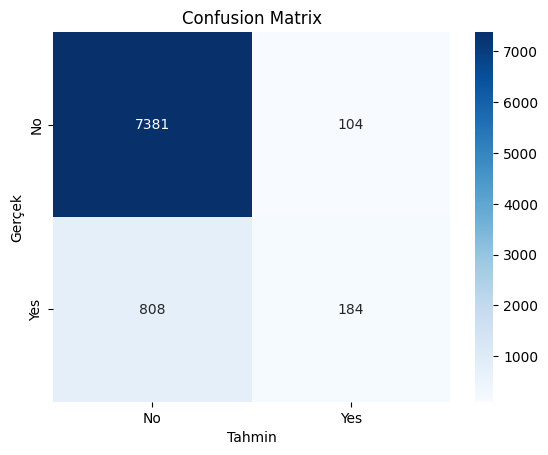

In [57]:
cm = confusion_matrix(y_val, y_pred, labels=["no", "yes"])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.title("Confusion Matrix")
plt.show()

In [58]:
balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

balanced_model.fit(X_train_scaled, y_train)

balanced_pred = balanced_model.predict(X_val_scaled)

In [59]:
print("Accuracy:", accuracy_score(y_val, balanced_pred))

print("Precision:", precision_score(
    y_val, balanced_pred, pos_label="yes"
))

print("Recall:", recall_score(
    y_val, balanced_pred, pos_label="yes"
))

print("F1 Score:", f1_score(
    y_val, balanced_pred, pos_label="yes"
))

Accuracy: 0.7604105225905391
Precision: 0.27884206045125587
Recall: 0.6602822580645161
F1 Score: 0.3920981741993415


In [60]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Balanced Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_val, y_pred),
        accuracy_score(y_val, balanced_pred)
    ],
    "Precision": [
        precision_score(y_val, y_pred, pos_label="yes"),
        precision_score(y_val, balanced_pred, pos_label="yes")
    ],
    "Recall": [
        recall_score(y_val, y_pred, pos_label="yes"),
        recall_score(y_val, balanced_pred, pos_label="yes")
    ],
    "F1 Score": [
        f1_score(y_val, y_pred, pos_label="yes"),
        f1_score(y_val, balanced_pred, pos_label="yes")
    ]
})

print(comparison.round(3))

                          Model  Accuracy  Precision  Recall  F1 Score
0           Logistic Regression     0.892      0.639   0.185     0.288
1  Balanced Logistic Regression     0.760      0.279   0.660     0.392


In [61]:
normal_prob = model.predict_proba(X_val_scaled)[
    :, list(model.classes_).index("yes")
]

balanced_prob = balanced_model.predict_proba(X_val_scaled)[
    :, list(balanced_model.classes_).index("yes")
]

print("Normal ROC-AUC:", roc_auc_score(y_val, normal_prob))

print(
    "Balanced ROC-AUC:",
    roc_auc_score(y_val, balanced_prob)
)

Normal ROC-AUC: 0.7867342211304329
Balanced ROC-AUC: 0.7864214989118022


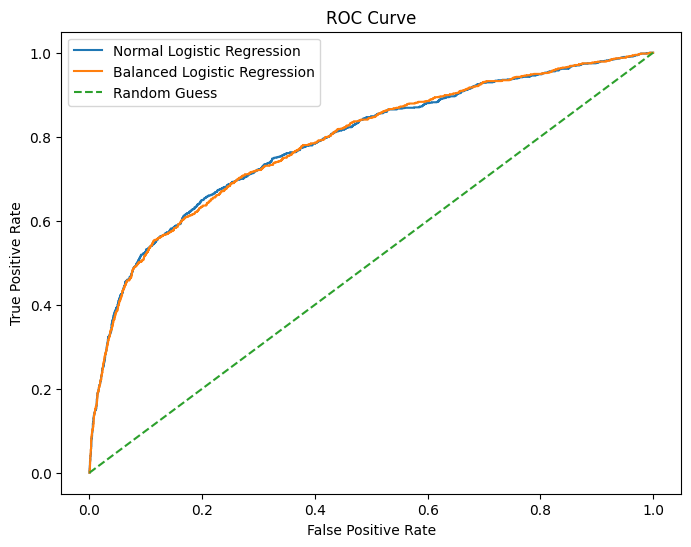

In [62]:
fpr_normal, tpr_normal, _ = roc_curve(
    y_val, normal_prob, pos_label="yes"
)

fpr_balanced, tpr_balanced, _ = roc_curve(
    y_val, balanced_prob, pos_label="yes"
)

plt.figure(figsize=(8, 6))

plt.plot(fpr_normal, tpr_normal, label="Normal Logistic Regression")
plt.plot(fpr_balanced, tpr_balanced, label="Balanced Logistic Regression")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [63]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_model.fit(X_train_scaled, y_train)

rf_pred = rf_model.predict(X_val_scaled)

In [64]:
rf_prob = rf_model.predict_proba(X_val_scaled)[
    :, list(rf_model.classes_).index("yes")
]

print("Accuracy:", accuracy_score(y_val, rf_pred))
print("Precision:", precision_score(y_val, rf_pred, pos_label="yes"))
print("Recall:", recall_score(y_val, rf_pred, pos_label="yes"))
print("F1 Score:", f1_score(y_val, rf_pred, pos_label="yes"))
print("ROC-AUC:", roc_auc_score(y_val, rf_prob))

print(classification_report(y_val, rf_pred))

Accuracy: 0.8928866344225551
Precision: 0.625
Recall: 0.21169354838709678
F1 Score: 0.31626506024096385
ROC-AUC: 0.7877039697674919
              precision    recall  f1-score   support

          no       0.90      0.98      0.94      7485
         yes       0.62      0.21      0.32       992

    accuracy                           0.89      8477
   macro avg       0.76      0.60      0.63      8477
weighted avg       0.87      0.89      0.87      8477



In [65]:
feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15))

                     Feature  Importance
1               num__balance    0.156842
0                   num__age    0.134525
2           num__day_of_week    0.120687
3              num__campaign    0.067615
4                 num__pdays    0.037490
48     cat__poutcome_success    0.032800
33      cat__contact_unknown    0.027111
5              num__previous    0.022843
31     cat__contact_cellular    0.020633
27           cat__housing_no    0.018278
22  cat__education_secondary    0.015416
28          cat__housing_yes    0.015139
7       cat__job_blue-collar    0.014862
15       cat__job_technician    0.014298
42            cat__month_may    0.014072


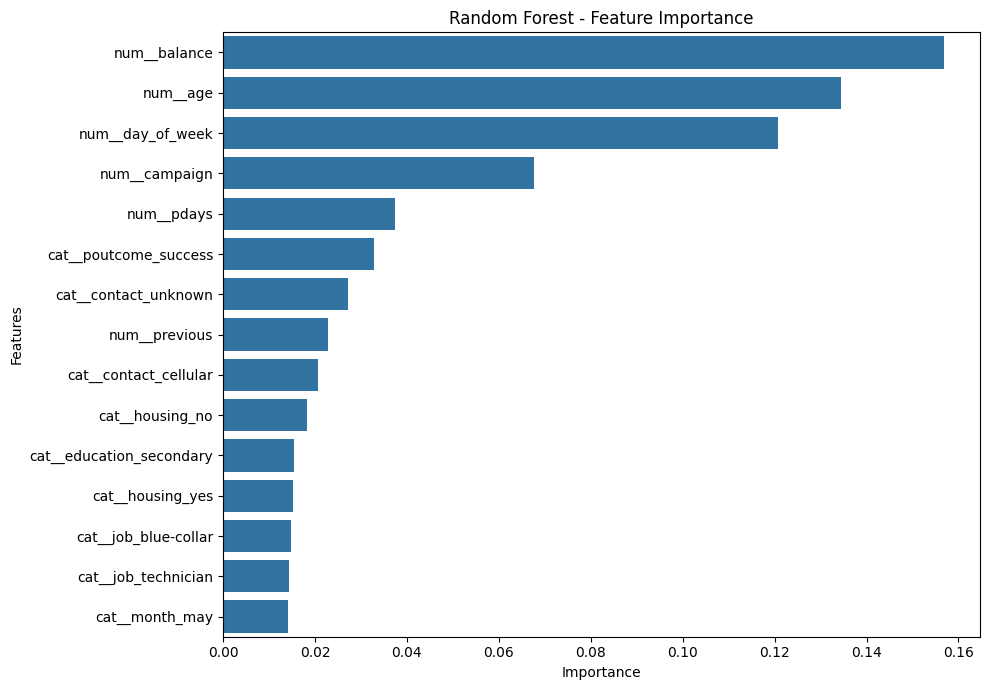

In [66]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [67]:
rf_prob = rf_model.predict_proba(X_val_scaled)[:,
    list(rf_model.classes_).index("yes")
]

In [68]:
for threshold in [0.2, 0.3, 0.4, 0.5, 0.6]:

    threshold_pred = (rf_prob >= threshold).astype(int)

    y_val_binary = (y_val == "yes").astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", precision_score(y_val_binary, threshold_pred))
    print("Recall:", recall_score(y_val_binary, threshold_pred))
    print("F1:", f1_score(y_val_binary, threshold_pred))


Threshold: 0.2
Precision: 0.38571428571428573
Recall: 0.5715725806451613
F1: 0.4606011372867587

Threshold: 0.3
Precision: 0.4653014789533561
Recall: 0.4122983870967742
F1: 0.43719935863174775

Threshold: 0.4
Precision: 0.5574387947269304
Recall: 0.29838709677419356
F1: 0.3887065003282994

Threshold: 0.5
Precision: 0.6257309941520468
Recall: 0.2157258064516129
F1: 0.32083958020989506

Threshold: 0.6
Precision: 0.6411483253588517
Recall: 0.1350806451612903
F1: 0.2231473771856786


In [69]:
for threshold in [0.10, 0.15, 0.20, 0.25, 0.30]:

    threshold_pred = (rf_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", precision_score(y_val_binary, threshold_pred))
    print("Recall:", recall_score(y_val_binary, threshold_pred))
    print("F1:", f1_score(y_val_binary, threshold_pred))


Threshold: 0.1
Precision: 0.2554233729881036
Recall: 0.7358870967741935
F1: 0.37922077922077924

Threshold: 0.15
Precision: 0.32694248234106965
Recall: 0.6532258064516129
F1: 0.4357767316745124

Threshold: 0.2
Precision: 0.38571428571428573
Recall: 0.5715725806451613
F1: 0.4606011372867587

Threshold: 0.25
Precision: 0.4290657439446367
Recall: 0.5
F1: 0.4618249534450652

Threshold: 0.3
Precision: 0.4653014789533561
Recall: 0.4122983870967742
F1: 0.43719935863174775


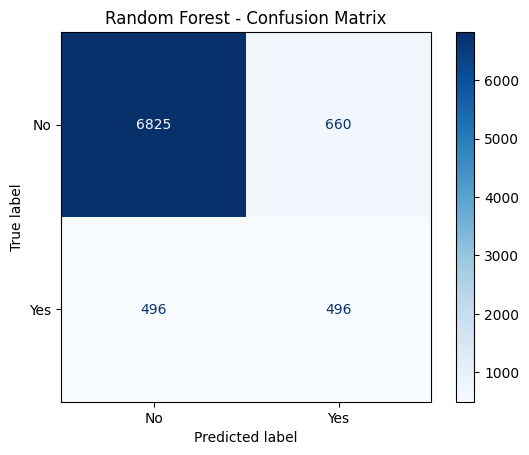

In [70]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

rf_final_pred = (rf_prob >= 0.25).astype(int)

cm = confusion_matrix(y_val_binary, rf_final_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot(cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.show()

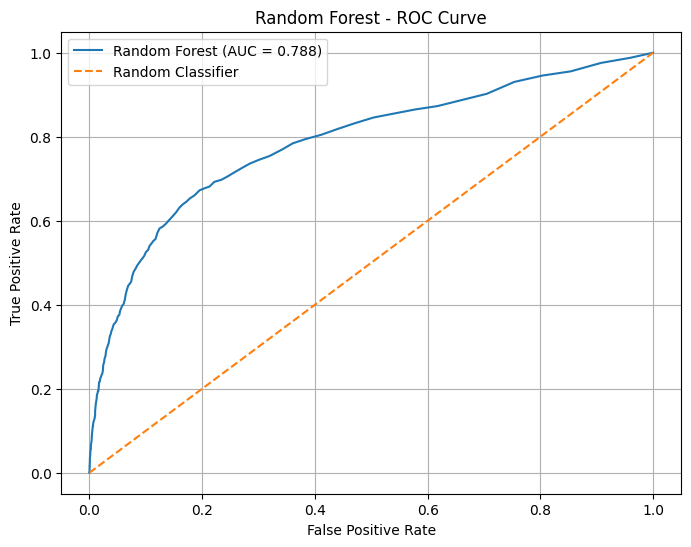

In [71]:
fpr, tpr, thresholds = roc_curve(y_val_binary, rf_prob)

roc_auc = roc_auc_score(y_val_binary, rf_prob)

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest - ROC Curve")
plt.legend()
plt.grid()
plt.show()

In [72]:
final_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

X_train_val_processed = final_preprocessor.fit_transform(X_train_val)

X_test_processed = final_preprocessor.transform(X_test)

final_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

final_model.fit(X_train_val_processed, y_train_val)

RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

In [73]:
test_prob = final_model.predict_proba(X_test_processed)[
    :, list(final_model.classes_).index("yes")
]

test_pred = (test_prob >= 0.25).astype(int)

y_test_binary = (y_test == "yes").astype(int)

In [74]:
print("Accuracy:", accuracy_score(y_test_binary, test_pred))
print("Precision:", precision_score(y_test_binary, test_pred))
print("Recall:", recall_score(y_test_binary, test_pred))
print("F1 Score:", f1_score(y_test_binary, test_pred))
print("ROC-AUC:", roc_auc_score(y_test_binary, test_prob))

print("\nClassification Report:")
print(classification_report(y_test_binary, test_pred))

Accuracy: 0.8666725648058038
Precision: 0.43737305348679756
Recall: 0.4886535552193646
F1 Score: 0.4615934262236513
ROC-AUC: 0.7919535392586308

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.92      0.92      9981
           1       0.44      0.49      0.46      1322

    accuracy                           0.87     11303
   macro avg       0.68      0.70      0.69     11303
weighted avg       0.87      0.87      0.87     11303

